# 04 · Modelagem e avaliação

**Vital Data Lab · Projeto 5 · GTI · CESAR School · 2026.2**

> ⚠️ **Base sintética.** Nenhum número deste notebook representa equipes, unidades ou resultados reais da Secretaria de Saúde do Recife.

Este notebook responde a quatro perguntas, cada uma com um modelo e uma avaliação honesta:

| Pergunta | Técnica | Onde está |
|---|---|---|
| Quanto cada ação muda cada item? | Regressão Ridge, um modelo por item | `prototipo/pulso/motor.py` (no app) |
| Com quem é justo comparar? | K-Means de território | `prototipo/pulso/motor.py` (no app) · `src/modelos/clusterizacao.py` |
| Em que faixa a equipe vai estar no próximo ciclo? | Random Forest | `src/modelos/classificador.py` (avaliado, fora do app) |
| Qual é o ponto fraco da equipe? | Regra de estabilidade | `src/recomendacao/ponto_fraco.py` |

Tudo é calculado por **um comando**, que também gera `reports/`. O notebook só lê e explica:

```bash
python -m src.etl.pipeline           # gera data/processed/base_analitica.csv
python -m src.modelos.treinar_avaliar  # avalia tudo e escreve reports/
```

In [1]:
import json, os, sys
from pathlib import Path

# O notebook mora em notebooks/; o código espera a raiz do repositório.
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
from IPython.display import Image, Markdown, display

from src.modelos import treinar_avaliar
treinar_avaliar.main()
R = json.loads(Path("reports/metricas_modelos.json").read_text(encoding="utf-8"))
fig = lambda nome: display(Image(filename=f"reports/figuras/{nome}", width=760))

[1/5] Random Forest na base comum (escolha de hiperparâmetros + teste temporal + CV)...


[2/5] Motor de sugestões e K-Means do protótipo...


[3/5] Ponto fraco e régua...


[4/5] Gráficos...


[5/5] Salvando relatórios...

================ RESUMO (base sintética) ================
Random Forest (teste 2026.1–2026.2): F1 macro 0.729 · recall Crítico 0.529
Regra 'fica onde está':              F1 macro 0.768 · recall Crítico 0.706
Motor do app: erro 2.409 pp com ações × 2.91 sem (17% menos) · correlação efeitos 0.996
K-Means do app: k=4 silhueta 0.458
Ponto fraco se repete: 11% (base comum) · régua: 523 mudam de zona
Arquivos em reports/


## 1. Random Forest: em que faixa a equipe vai estar no próximo ciclo?

**Por que o próximo ciclo:** a faixa do ciclo atual é só a soma dos eixos cortada em 500 e 750. Prever isso seria vazamento: o modelo copiaria a soma e acertaria 100% sem valor nenhum.

**Protocolo:**
1. **Teste temporal:** treina com o passado e testa nos pares cujo alvo é 2026.1 ou 2026.2, como seria em produção.
2. **Hiperparâmetros** escolhidos por validação cruzada **só no treino**.
3. **Validação cruzada agrupada por equipe** (5 partes): a mesma equipe nunca aparece no treino e no teste ao mesmo tempo.
4. **Duas linhas de base:** classe mais comum e "a equipe fica onde está" (persistência).
5. **Regras do programa:** desclassificada fica fora, nunca vira zero. O Bloco A sem quórum de 30% entra como ausente.

In [2]:
rf = R["rf"]
print(f"{rf['n_pares']} pares · {rf['n_equipes']} equipes · treino {rf['n_treino']} · teste {rf['n_teste']}")
print("Distribuição no teste:", rf["distribuicao_teste"])
print("Hiperparâmetros escolhidos no treino:", rf["hiperparametros"])
pd.DataFrame({
    "Random Forest (teste temporal)": rf["random_forest_teste_temporal"],
    "Regra 'fica onde está'": rf["baseline_persistencia"],
    "Classe mais comum": rf["baseline_classe_comum"],
    "Random Forest (CV por equipe)": rf["random_forest_cv_por_equipe"],
    "Persistência (mesmas linhas da CV)": rf["persistencia_cv_mesmas_linhas"],
}).T

1122 pares · 132 equipes · treino 880 · teste 242
Distribuição no teste: {'Crítico': 17, 'Atenção': 176, 'Excelência': 49}
Hiperparâmetros escolhidos no treino: {'min_samples_leaf': 3, 'class_weight': 'balanced', 'n_estimators': 400, 'random_state': 42}


,acuracia,f1_macro,recall_critico,precisao_critico
Random Forest (teste temporal),0.826,0.729,0.529,0.692
Regra 'fica onde está',0.839,0.768,0.706,0.750
Classe mais comum,0.727,0.281,0.000,0.000
Random Forest (CV por equipe),0.856,0.746,0.685,0.708
Persistência (mesmas linhas da CV),0.856,0.751,0.707,0.663


In [3]:
print("Grade de hiperparâmetros (validação cruzada só no treino, ordenada por F1 macro):")
pd.DataFrame(rf["grade_cv_treino"])

Grade de hiperparâmetros (validação cruzada só no treino, ordenada por F1 macro):


,min_samples_leaf,class_weight,acuracia,f1_macro,recall_critico,precisao_critico
0,3,balanced,0.861,0.738,0.640,0.727
1,3,None,0.872,0.735,0.533,0.833
2,1,None,0.869,0.731,0.533,0.800
3,8,balanced,0.819,0.719,0.773,0.558
4,8,None,0.866,0.716,0.507,0.826
5,1,balanced,0.843,0.646,0.493,0.860


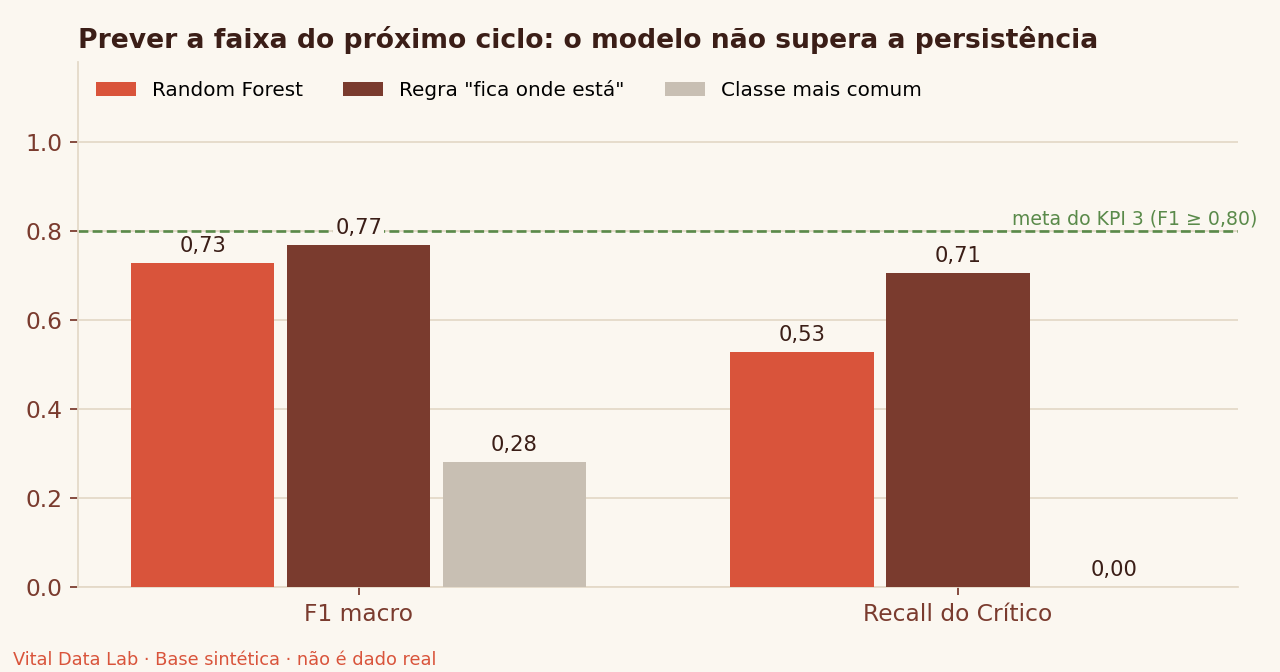

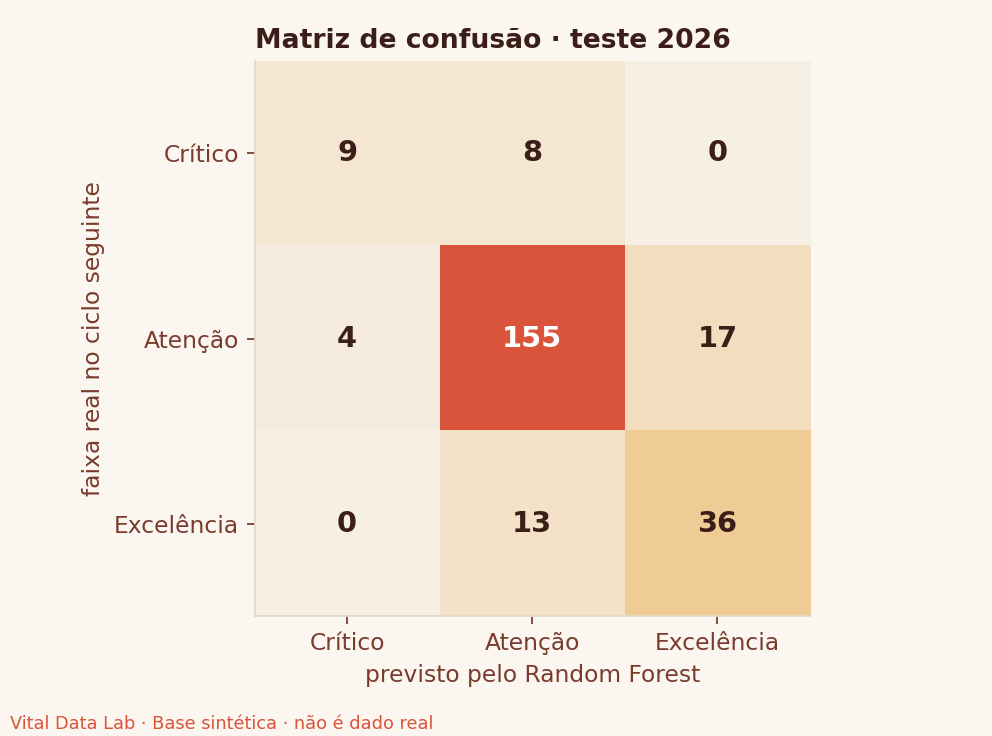

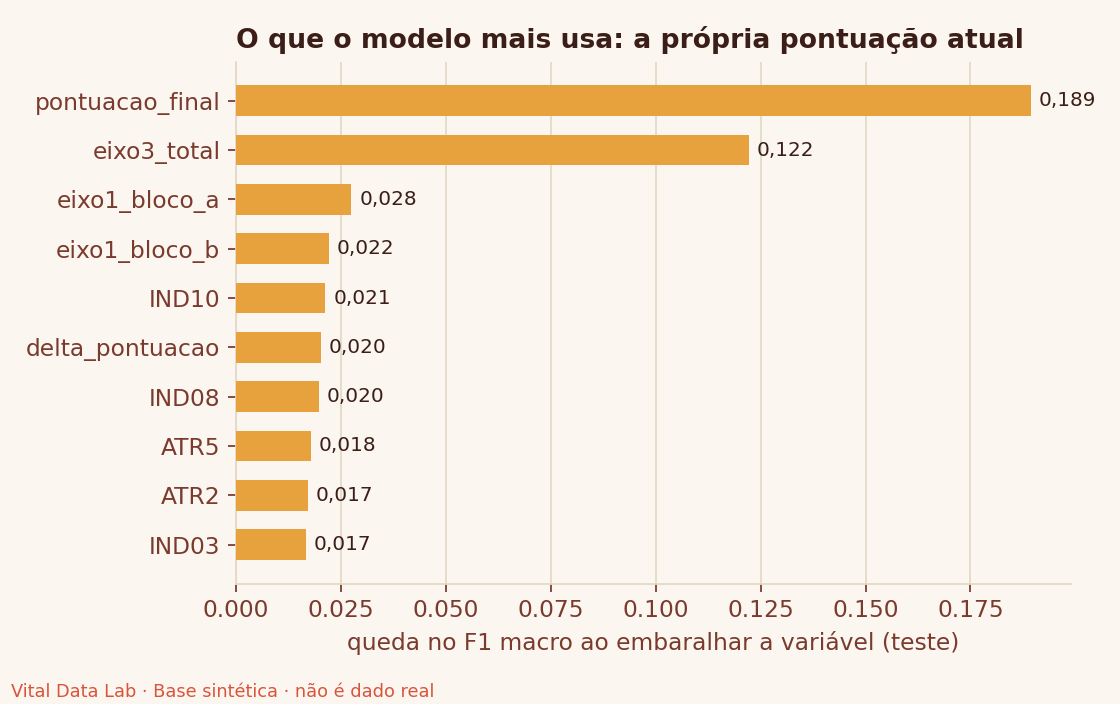

In [4]:
fig("01_rf_vs_baselines.png"); fig("02_matriz_confusao.png"); fig("03_importancia_variaveis.png")

In [5]:
m = rf["random_forest_teste_temporal"]; p = rf["baseline_persistencia"]
display(Markdown(f'''**Leitura.** O Random Forest supera com folga a classe mais comum (F1 {m["f1_macro"]} × {rf["baseline_classe_comum"]["f1_macro"]}),
mas **não supera a regra "fica onde está"** (F1 {p["f1_macro"]}; recall do Crítico {p["recall_critico"]} × {m["recall_critico"]}).
Das {rf["n_teste"]} equipes do teste, só **{rf["equipes_que_mudaram_de_faixa_no_teste"]}** mudaram de faixa, e o modelo acertou
**{rf["rf_acerto_entre_as_que_mudaram"]:.0%}** delas. A variável que ele mais usa é a pontuação atual.

**KPI 3 (F1 macro ≥ 0,80): não atingido ({m["f1_macro"]}).**

**Decisão:** o Random Forest **não entra no app**. Um alerta que não bate a regra mais simples não pode ser
apresentado ao gestor como previsão (Rudin, 2019). O valor está em recomendar a ação, como mostra a seção 2.'''))

**Leitura.** O Random Forest supera com folga a classe mais comum (F1 0.729 × 0.281),
mas **não supera a regra "fica onde está"** (F1 0.768; recall do Crítico 0.706 × 0.529).
Das 242 equipes do teste, só **39** mudaram de faixa, e o modelo acertou
**15%** delas. A variável que ele mais usa é a pontuação atual.

**KPI 3 (F1 macro ≥ 0,80): não atingido (0.729).**

**Decisão:** o Random Forest **não entra no app**. Um alerta que não bate a regra mais simples não pode ser
apresentado ao gestor como previsão (Rudin, 2019). O valor está em recomendar a ação, como mostra a seção 2.

## 2. Motor de sugestões (Ridge): o modelo que está no app

Para cada item dos três eixos, uma regressão Ridge explica a variação de um ciclo para o outro a partir do ponto de partida, do território e das ações pactuadas. As interações deixam o efeito de cada ação variar com o espaço que o item tem para crescer e com a cobertura de ACS. Assim o motor separa o efeito da ação da volta natural à média.

O protótipo usa um gerador sintético próprio, e por isso dá para conferir se o motor **reencontra** os efeitos usados para gerar os dados.

equipes no protótipo                                 193
transições equipe×ciclo                             1351
erro com as ações (pp)                             2.409
erro sem as ações (pp)                              2.91
redução do erro                                      17%
correlação efeito aprendido × gerador              0.996
ganho médio do mutirão de sábado (pp)               1.83
ação de maior ganho médio                acesso_avancado
Name: motor, dtype: object

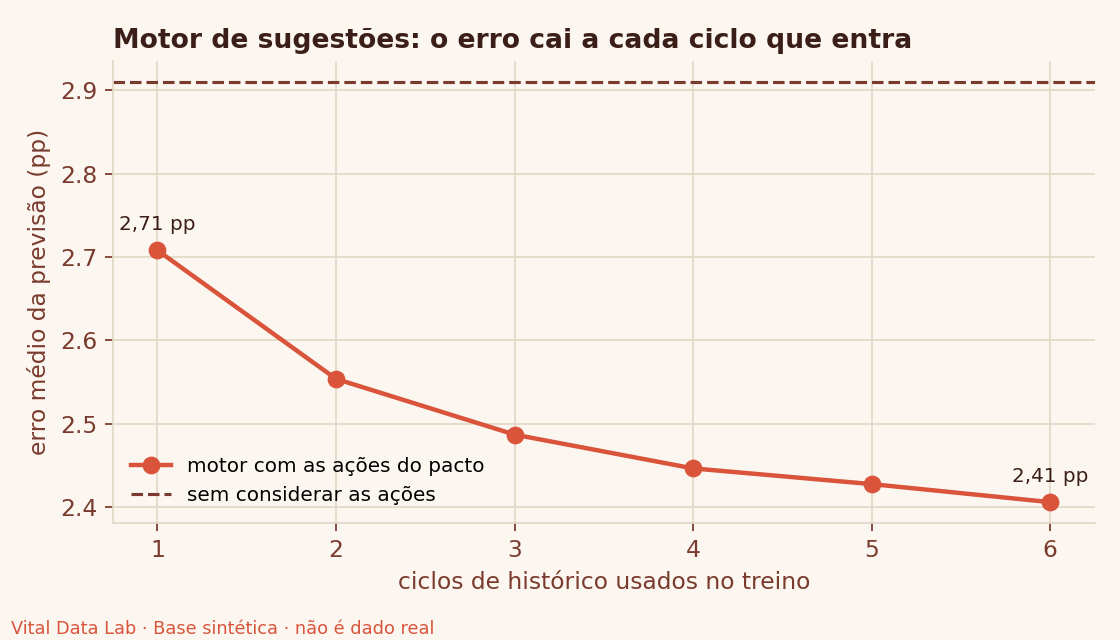

In [6]:
mo = R["prototipo"]["motor"]
display(pd.Series({
    "equipes no protótipo": R["prototipo"]["n_equipes"],
    "transições equipe×ciclo": R["prototipo"]["n_transicoes"],
    "erro com as ações (pp)": mo["mae_com_acoes_pp"],
    "erro sem as ações (pp)": mo["mae_sem_acoes_pp"],
    "redução do erro": f"{mo['reducao_erro']:.0%}",
    "correlação efeito aprendido × gerador": mo["correlacao_efeito_aprendido_vs_gerador"],
    "ganho médio do mutirão de sábado (pp)": mo["ganho_medio_mutirao_sabado_pp"],
    "ação de maior ganho médio": mo["acao_de_maior_ganho_medio"],
}, name="motor"))
fig("04_motor_curva_aprendizado.png")

**Limite declarado:** no protótipo, os efeitos verdadeiros são conhecidos porque nós geramos os dados. Com dado real essa conferência não existe; o que vale é o erro de previsão do ciclo seguinte, medido a cada ciclo que entra (a curva acima).

## 3. K-Means de território: com quem é justo comparar

As equipes são agrupadas por IDHM, saneamento e log da renda. Cada equipe é comparada com as de território parecido, não com a média da cidade (CP-FIT). O app usa **k = 4**, que é escolha de domínio: quatro níveis de vulnerabilidade que o gestor consegue ler. A silhueta mostra que essa estrutura é razoável.

Silhueta por k: {'2': 0.559, '3': 0.472, '4': 0.458, '5': 0.446, '6': 0.441, '7': 0.437}
k do app = 4 (silhueta 0.458) · maior silhueta em k = 2
Este módulo reproduz exatamente os grupos do app: True


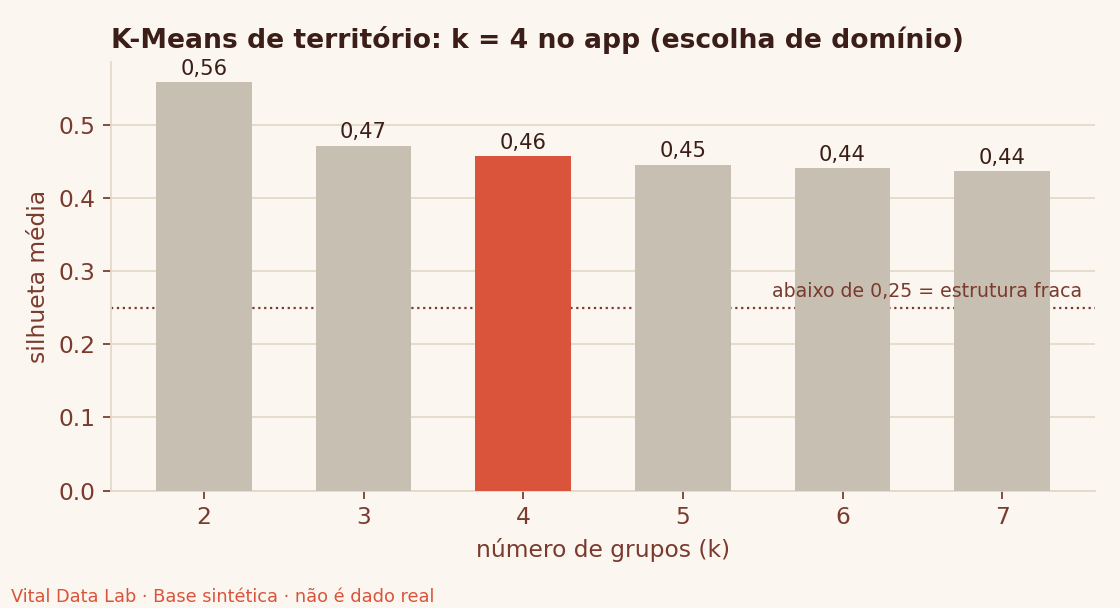

In [7]:
km = R["prototipo"]["kmeans_territorio"]
print("Silhueta por k:", km["silhueta_por_k"])
print(f"k do app = {km['k_app']} (silhueta {km['silhueta_k_app']}) · maior silhueta em k = {km['k_maior_silhueta']}")
print("Este módulo reproduz exatamente os grupos do app:", km["reproduz_grupos_do_app"])
fig("05_kmeans_silhueta.png")

## 4. Ponto fraco: só apontar o que se repete

O professor alertou que, na base comum, o item mais baixo de uma equipe muda de um ciclo para o outro em quase todos os casos. Medimos na nossa base tratada e aplicamos a regra **"mais baixo em 3 dos últimos 3 ciclos"**.

Base comum: o indicador mais baixo se repete em 11% dos 1122 pares (muda em 89%).
Pela regra 3 de 3: 0 de 129 equipes têm ponto fraco defensável no último ciclo.
Gerador do protótipo: se repete em 79% (diferença do gerador, não da realidade).


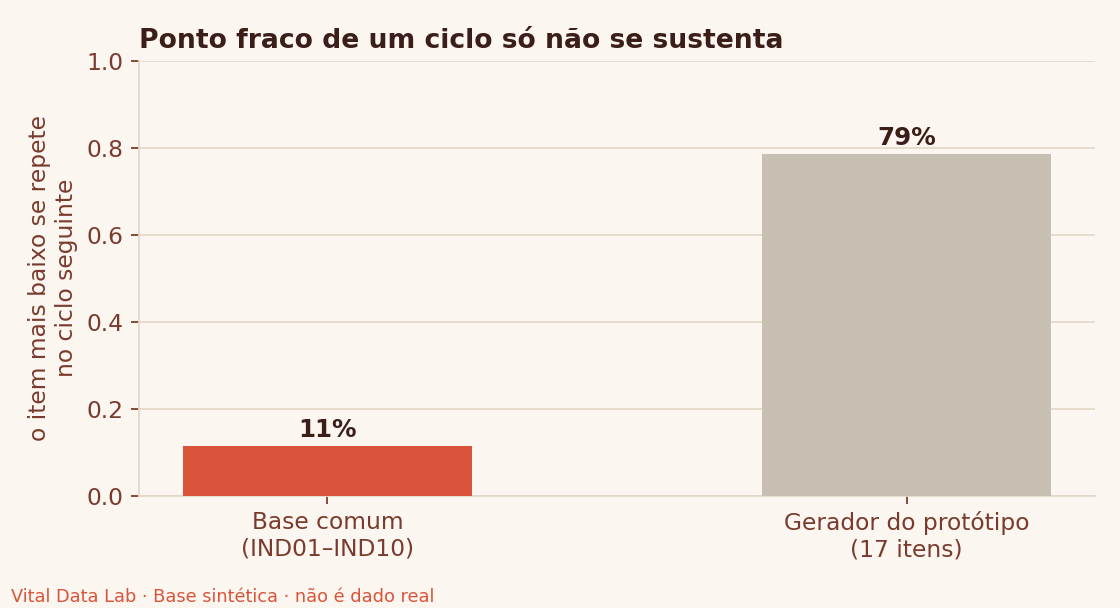

In [8]:
pf, regra = R["ponto_fraco_base_comum"], R["ponto_fraco_regra_base_comum"]
print(f"Base comum: o indicador mais baixo se repete em {pf['repete']:.0%} dos {pf['pares']} pares (muda em {pf['muda']:.0%}).")
print(f"Pela regra 3 de 3: {regra['com_ponto_fraco']} de {regra['equipes']} equipes têm ponto fraco defensável no último ciclo.")
print(f"Gerador do protótipo: se repete em {R['prototipo']['ponto_fraco']['repete']:.0%} (diferença do gerador, não da realidade).")
fig("06_ponto_fraco_estabilidade.png")

**Leitura:** com a base comum, a resposta honesta é *"não há ponto fraco defensável"*. O app mostra os itens abaixo dos pares, mas não elege um "vilão" da equipe. Quando o motor for ligado à base comum ou à real, essa regra entra antes de qualquer frase do tipo "o ponto fraco é X".

## 5. Régua: Manual × dicionário

O semáforo de ação (500/750) é do projeto. A zona de certificação tem duas versões, a do Manual (900/800/600/400) e a do dicionário de dados (850/700/550/400), e elas não batem.

In [9]:
print(f"Equipes-ciclo que mudam de zona entre as duas réguas: {R['regua']['mudam_de_zona']}")
pd.DataFrame(R["regua"]["manual_x_dicionario"]).fillna(0).astype(int)

Equipes-ciclo que mudam de zona entre as duas réguas: 523


,Aperfeiçoamento,Crítica,Excelência,Insuficiente,Qualidade
Aperfeiçoamento,506,0,0,0,311
Crítica,195,198,0,0,0
Excelência,0,0,7,0,0
Insuficiente,0,0,0,22,0
Qualidade,0,0,17,0,48


## Conclusões e limites

1. **O motor de ações é o produto.** Com as ações do pacto, o erro de previsão cai 17%, e o motor reencontra os efeitos verdadeiros do gerador.
2. **Prever a faixa não agrega.** A faixa é estável de um ciclo para o outro, e a regra "fica onde está" já acerta o que o Random Forest acerta. Ele fica documentado como evidência, fora do app.
3. **Ponto fraco só quando se repete.** Na base comum quase nunca se repete.
4. **Limites:** a base é sintética. A adesão das equipes é voluntária, então a ausência de uma equipe pode ser escolha dela, e isso gera viés de seleção. O teste temporal tem só 17 casos de Crítico. Com dado real, a avaliação deve ser repetida a cada ciclo rodando o mesmo comando.